# Protocolo temporal corregido y baseline — Fase 4.2

Esta fase aplica **v2, un protocolo explícitamente aproximado**, conservando todas las reservas y los 14 predictores. Corrige la espera innecesaria hasta la salida prevista y añade una comprobación de disponibilidad para prueba. No certifica snapshots iniciales, una fecha exacta de alta o un cierre real del PMS.

Se revisaron los informes y código de las fases previas. Los resultados/manifiesto v1 se conservan en `reports/historico/protocolo_v1/`. **Las métricas v1 y los umbrales estudiados en 4.1 no son la referencia para comparar modelos con v2.** No se optimiza, no se evalúa prueba ni se comienza fase 5.

## 1. Evidencia y decisiones previas al ajuste
El [artículo original](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/) describe la fecha del último estado y valores recuperados de cambios cercanos a la llegada. No acredita la disponibilidad inicial de cada predictor. La publicación en línea es de noviembre de 2018; **no equivale a cierre operativo**. La nota de fuentes conserva la referencia y sus límites.

- Alta aproximada: llegada prevista menos `lead_time`.
- Disponibilidad aproximada: `reservation_status_date + 1 día`, solo como metadato.
- Cortes de cohortes: julio de 2016 y enero de 2017, sin optimizarlos por métricas.
- Cierre de observación asumido: **01/12/2018 exclusivo**, inicio del mes posterior a la publicación, no inferido del último caso de prueba.
- Cierre operativo realmente acreditado: **desconocido**.

Las reglas se fijan y guardan antes de ajustar el baseline. La alternativa de usar todas las etiquetas finales en cortes anteriores se rechaza por información futura. No se adopta un horizonte arbitrario que suprima reservas difíciles ni cortes por llegada como sustituto de creación.

In [1]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Construir el protocolo histórico v2 y registrar sus reglas antes del baseline.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
from pathlib import Path
import sys
import json
import hashlib
import io
import unittest
import pandas as pd
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/raw/hotel_bookings.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.splitting import PROTOCOL_V2
from src.temporal_protocol import build_protocol, run_protocol

REPORT_PATH = PROJECT_ROOT / "reports"
protected_paths = [PROJECT_ROOT / "data/raw/hotel_bookings.csv", PROJECT_ROOT / "data/processed/hotel_bookings_prepared.csv"]
protected_paths += list((REPORT_PATH / "historico/protocolo_v1").glob("*"))
# Calcular una huella determinista para trazabilidad; no usarla como característica predictiva.
protected_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in protected_paths if p.is_file()}
X, y, metadata, assigned, protocol = build_protocol(PROJECT_ROOT)
display(pd.Series(PROTOCOL_V2, name="regla").to_frame())

,regla
version,v2_estado_fechado_aproximado
validation_start,2016-07-01
test_start,2017-01-01
assumed_as_of_exclusive,2018-12-01
accredited_as_of,None
status_recording_lag_days,1
publication_date_reference,2018-11-29
as_of_basis,Supuesto retrospectivo: comienzo del mes sigui...
availability_rule,"reservation_status_date + 1 día, estrictamente..."


## 2. Particiones antes de ver métricas
**Pregunta:** ¿qué cambia sin introducir resultados posteriores al corte?

Se usa una regla idéntica de disponibilidad aproximada para entrenamiento, validación y prueba. El proxy debe preceder estrictamente a su corte. Las filas no elegibles quedan identificadas, no se borran ni se trasladan a otro periodo. Prueba mantiene todos sus IDs históricos y queda fuera del ajuste.

In [2]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Examinar población, reincorporaciones y exclusiones bajo sus proxies temporales.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(pd.DataFrame(protocol["particiones"]))
# Leer las columnas y filas solicitadas; los filtros de esta llamada determinan la población disponible.
display(pd.read_csv(REPORT_PATH / "protocolo_4_2_transicion.csv"))
# Leer las columnas y filas solicitadas; los filtros de esta llamada determinan la población disponible.
display(pd.read_csv(REPORT_PATH / "protocolo_4_2_reincorporadas_perfil.csv"))
# Leer las columnas y filas solicitadas; los filtros de esta llamada determinan la población disponible.
display(pd.read_csv(REPORT_PATH / "protocolo_4_2_apartadas_por_mes.csv"))
# Comprobar tamaños esperados para detectar pérdidas de filas o desalineación.
assert len(X) == len(y) == len(metadata) == len(assigned) == 119390
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert protocol["prueba_mismos_ids_v1"] and protocol["sin_solapamientos"]
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert protocol["reincorporadas"] == 9822 and protocol["pendientes_v2"] == 20564
print(f"Reincorporadas: {protocol['reincorporadas']:,} ({protocol['proporcion_reincorporada']:.2%}); pendientes: {protocol['pendientes_v2']:,}")

,particion,registros,no_canceladas,canceladas,tasa_cancelacion,lead_time_mediana,proxy_min,proxy_max,llegada_min,llegada_max,disponibilidad_proxy_min,disponibilidad_proxy_max
0,entrenamiento,54164,31090,23074,0.426003,68.0,2013-06-24,2016-06-29,2015-07-01,2017-05-31,2014-10-18,2016-06-30
1,validacion,18097,10344,7753,0.428414,37.0,2016-07-01,2016-12-30,2016-07-01,2017-08-28,2016-07-02,2016-12-31
2,prueba_reservada,26565,18163,8402,0.316281,40.0,2017-01-01,2017-08-31,2017-01-01,2017-08-31,2017-01-02,2017-09-15
3,no_madura_entrenamiento,12089,9346,2743,0.226900,185.0,2015-02-20,2016-06-30,2016-06-14,2017-08-29,2016-07-01,2017-08-31
4,no_madura_validacion,8475,6223,2252,0.265723,163.0,2016-07-01,2016-12-31,2016-12-13,2017-08-31,2017-01-01,2017-09-11
5,no_madura_prueba,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,particion,entrenamiento,validacion,prueba_reservada,no_madura_entrenamiento,no_madura_validacion,no_madura_prueba
0,entrenamiento,48428,0,0,0,0,0
1,no_madura_entrenamiento,5736,0,0,12089,0,0
2,no_madura_validacion,0,4086,0,0,8475,0
3,prueba_reservada,0,0,26565,0,0,0
4,validacion,0,14011,0,0,0,0


,destino,reincorporadas,canceladas,no_canceladas,lead_time_mediana
0,entrenamiento,5736,5734,2,250.0
1,validacion,4086,4086,0,158.0


,grupo_v1,mes_proxy,reservas,reincorporadas,pendientes
0,no_madura_entrenamiento,2015-02,60,0,60
1,no_madura_entrenamiento,2015-04,23,0,23
2,no_madura_entrenamiento,2015-05,2,1,1
3,no_madura_entrenamiento,2015-06,2,1,1
4,no_madura_entrenamiento,2015-07,1160,1071,89
5,no_madura_entrenamiento,2015-08,128,21,107
6,no_madura_entrenamiento,2015-09,334,142,192
7,no_madura_entrenamiento,2015-10,963,122,841
8,no_madura_entrenamiento,2015-11,634,309,325
9,no_madura_entrenamiento,2015-12,686,283,403


Reincorporadas: 9,822 (32.32%); pendientes: 20,564


**Interpretación.** V2 incorpora reservas cuyo resultado ya está fechado antes del corte, aunque la llegada prevista sea posterior. Una llegada futura no equivale por sí misma a una etiqueta futura si ya hay cancelación registrada, bajo el supuesto de disponibilidad.

Se reincorporan 5.736 a entrenamiento y 4.086 a validación. Las últimas son cancelaciones: la distribución de clases cambia materialmente. No se afirma haber eliminado el sesgo; quedan 20.564 pendientes y las reservas observadas a tiempo no representan toda la cohorte de altas. La llegada máxima de entrenamiento puede estar en 2017 sin que su estado fechado exceda junio de 2016.

## 3. Recalcular el mismo baseline
**Pregunta:** ¿qué referencia obtenemos en la nueva población elegible?

Se mantiene la fábrica del pipeline y los hiperparámetros originales: LogisticRegression(C=1, solver='lbfgs', max_iter=2000, class_weight=None, random_state=42), umbral 0,5. Los imputadores, categorías y escalas se ajustan únicamente con el nuevo entrenamiento y se comprueban sus estadísticas. No se transforma ni predice prueba.

,accuracy,precision,recall,f1,roc_auc
mayoritario,0.571586,0.000000,0.000000,0.000000,0.500000
regresion_logistica,0.747085,0.807633,0.537727,0.645606,0.820718


,Predice no cancela,Predice cancela
Real no cancela,9351,993
Real cancela,3584,4169


,protocolo,modelo,accuracy,precision,recall,f1,roc_auc
0,v1_historia_no_comparable_como_ranking,mayoritario,0.738277,0.000000,0.000000,0.000000,0.500000
1,v1_historia_no_comparable_como_ranking,regresion_logistica,0.744344,0.533597,0.184074,0.273723,0.700440
2,v2_vigente,mayoritario,0.571586,0.000000,0.000000,0.000000,0.500000
3,v2_vigente,regresion_logistica,0.747085,0.807633,0.537727,0.645606,0.820718


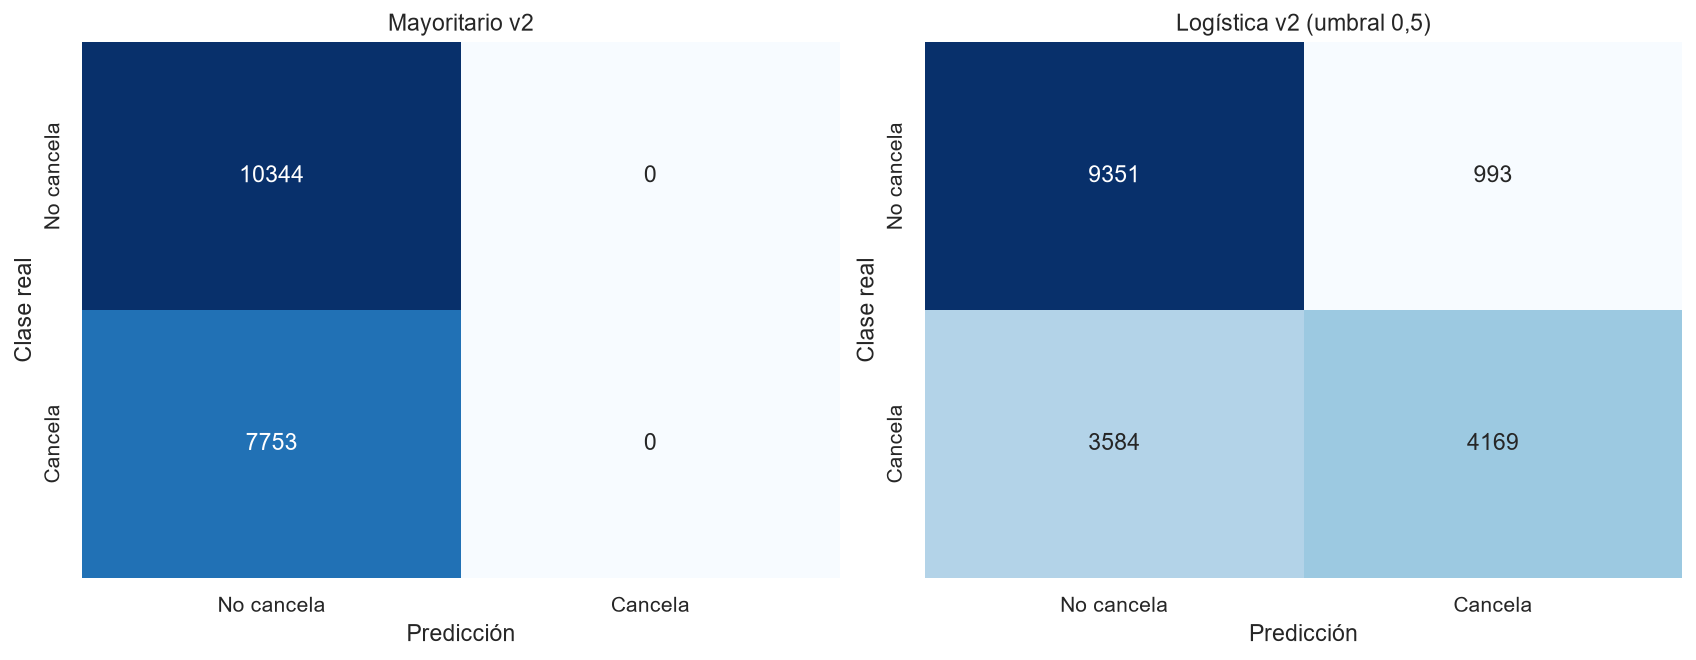

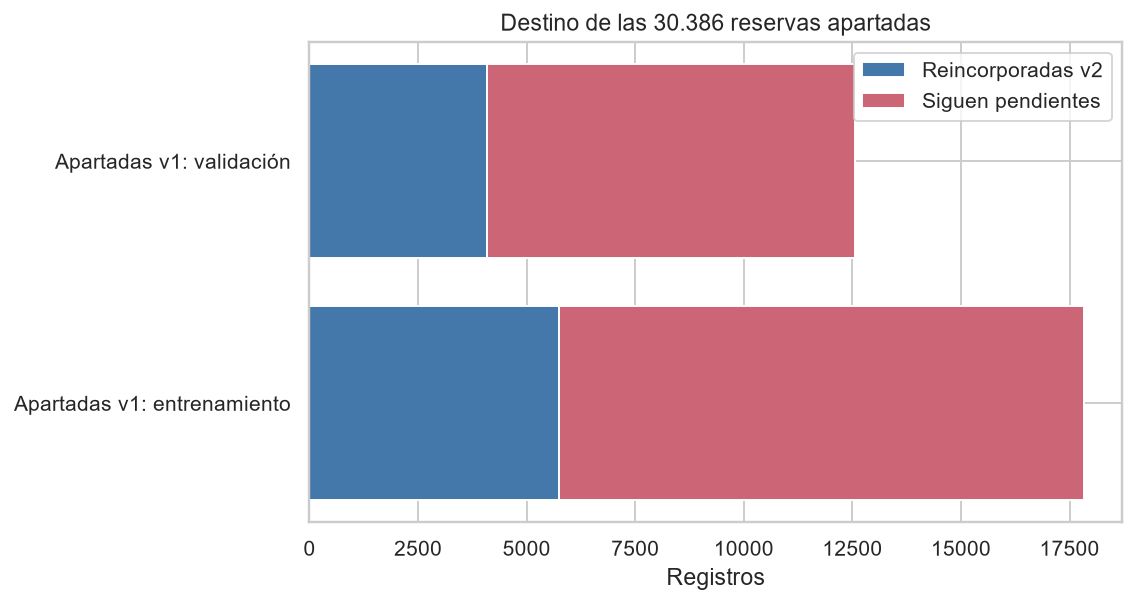

In [3]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Ajustar y evaluar el baseline de aquella fase histórica, separado del resultado final v3.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
protocol, result = run_protocol(PROJECT_ROOT)
metrics = pd.DataFrame({name: {k: v for k, v in row.items() if k != "matriz_confusion"} for name, row in result["metricas"].items()}).T
display(metrics)
display(pd.DataFrame(result["metricas"]["regresion_logistica"]["matriz_confusion"],
    index=["Real no cancela", "Real cancela"], columns=["Predice no cancela", "Predice cancela"]))
# Leer las columnas y filas solicitadas; los filtros de esta llamada determinan la población disponible.
display(pd.read_csv(REPORT_PATH / "protocolo_4_2_comparacion_descriptiva.csv"))
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert result["auditoria_fit"]["n_test_solo_transformadas"] == 0
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert not result["prueba_evaluada"] and not result["auditoria_fit"]["test_predict_ejecutado"]
display(Image(filename=str(REPORT_PATH / "figures/protocolo_4_2_confusion_validacion.png")))
display(Image(filename=str(REPORT_PATH / "figures/protocolo_4_2_reincorporacion.png")))

**Interpretación.** La comparación de v1 y v2 describe cambios de protocolo y composición; el algoritmo es el mismo. Por eso una diferencia en F1, recall o AUC no es una mejora atribuible exclusivamente al modelo. Solo las cifras v2 pueden servir como referencia dentro del protocolo actual, y únicamente con su alcance aproximado. No se trasladan los umbrales de 4.1 ni se ajusta uno nuevo.

## 4. Integridad, pruebas y límites de uso
**Pregunta:** ¿se preservaron las fuentes y el conjunto de prueba?

In [4]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Comprobar resultados y archivos protegidos de la ejecución histórica.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
# Seleccionar las pruebas de esta llamada; los conjuntos históricos pueden incluir entrenamientos.
suite = unittest.defaultTestLoader.discover(str(PROJECT_ROOT / "tests"))
log = io.StringIO()
# Ejecutar la batería indicada y conservar su salida; comprobar qué pruebas admite esta fase.
test_result = unittest.TextTestRunner(stream=log, verbosity=2).run(suite)
print(log.getvalue())
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert test_result.wasSuccessful()
for filename, expected in protected_hashes.items():
    # La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == expected
verification_path = REPORT_PATH / "protocolo_4_2_verificacion.json"
verification = json.loads(verification_path.read_text(encoding="utf-8"))
verification.update({"tests_ejecutados": test_result.testsRun, "fallos": len(test_result.failures),
    "errores": len(test_result.errors), "cwd_ejecucion": "raiz" if Path.cwd() == PROJECT_ROOT else "notebooks",
    "notebook_completado": True, "fase_5_iniciada": False})
# Persistir documentación o metadatos para revisar las decisiones sin volver a ejecutar el modelo.
verification_path.write_text(json.dumps(verification, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series({k: verification[k] for k in ["tests_ejecutados", "fallos", "errores", "historico_v1_intacto", "ids_prueba_iguales_v1", "test_predicho", "test_evaluado", "referencias_sin_cambios"]}, name="comprobacion").to_frame())
print("Informe: reports/fase_4_2_protocolo_temporal.md")

test_reliability_includes_zero_one_and_preserves_totals (test_audit_baseline.AuditBaselineTests.test_reliability_includes_zero_one_and_preserves_totals) ... ok
test_temporal_scenarios_are_strict_and_do_not_reassign (test_audit_baseline.AuditBaselineTests.test_temporal_scenarios_are_strict_and_do_not_reassign) ... ok
test_threshold_tie_and_error_counts (test_audit_baseline.AuditBaselineTests.test_threshold_tie_and_error_counts) ... ok
test_confusion_orientation_and_trivial_auc (test_baseline.BaselineTests.test_confusion_orientation_and_trivial_auc) ... ok
test_dates_and_maturity_boundaries (test_baseline.BaselineTests.test_dates_and_maturity_boundaries) ... ok
test_duplicate_group_cannot_cross_partitions (test_baseline.BaselineTests.test_duplicate_group_cannot_cross_partitions) ... ok
test_invalid_dates_and_cut_order_fail (test_baseline.BaselineTests.test_invalid_dates_and_cut_order_fail) ... ok
test_all_rows_and_duplicates_preserved_without_mutation (test_preparation.PreparationTests.t

,comprobacion
tests_ejecutados,18
fallos,0
errores,0
historico_v1_intacto,True
ids_prueba_iguales_v1,True
test_predicho,False
test_evaluado,False
referencias_sin_cambios,105


Informe: reports/fase_4_2_protocolo_temporal.md


**Conclusión.** No existe una evaluación estricta acreditada al crear la reserva con estos archivos. V2 es la aproximación vigente: explicita las fechas, reduce esperas innecesarias, conserva pendientes y protege prueba. El cierre es asumido; los valores de los predictores no están certificados como snapshots iniciales y permanece selección por disponibilidad.

Se puede proponer una comparación académica exploratoria de algoritmos del curso bajo este contrato, si el usuario la autoriza. No se puede afirmar validez operativa al alta, ausencia total de fuga temporal o utilidad económica solo por las métricas. Para eso hacen falta logs y seguimiento acreditado. **Fin de fase 4.2; no se avanza a fase 5.**